In [ ]:
fl  = 'R1233zd(E)'
cpw = 4180.0
T_DC_out = 60 + 273.15 # Water temp. coming out of DC (K)
m_w = 28.7 # Water loop flow rate for DC cooling (kg/s) 
PP, SH, SC = 5.0, 4.0, 0 # Pinch (K), superheat (K), subcool (K)
eta_t, eta_p = 0.8, 0.75 # Efficiencies of ORC turbine and pump

def orc(T_evap, T_cond):
    P_e, P_c = PS('P','T',T_evap,'Q',1,fl), PS('P','T',T_cond,'Q',1,fl) # Gives evaporator and condenser pressures - check if this should be 0 for saturated liquid

    # 1: pump inlet (sat. liquid at T_cond, minus subcooling)
    T1 = T_cond - SC # Pump inlet temp.
    h1 = PS('H','T',T1,'Q',0,fl);  s1 = PS('S','T',T1,'Q',0,fl) # Enthalpy and entropy at pump inlet
    
    # 2: pump exit
    h2_ideal = PS('H','P',P_e,'S',s1,fl) # Calculates the enthalpy at pump exit if it were isentropic (pump just increases pressure from P_c to P_e and entropy stays the same)
    h2 = h1 + (h2_ideal - h1)/eta_p # Calculates the actual enthalpy at pump exit, accounting for pump efficiency (note, isentropic efficiency is used)
    
    # 3: WF liquid preheated to evaporation temperature
    h3 = PS('H','T',T_evap,'Q',0,fl)  # Enthalpy of saturated liquid at evaporator temperature
    
    # 4: turbine inlet
    h4 = PS('H','T',T_evap+SH,'P',P_e,fl);  s4 = PS('S','T',T_evap+SH,'P',P_e,fl) # Calculates the enthalpy and entropy at turbine inlet (superheated vapor)
    
    # 5: turbine outlet
    h5_ideal = PS('H','P',P_c,'S',s4,fl) # Calculates the enthalpy at turbine exit if it were isentropic (turbine just decreases pressure from P_e to P_c and entropy stays the same)
    h5   = h4 - eta_t*(h4 - h5_ideal) # Calculates the actual enthalpy at turbine exit, accounting for turbine efficiency (note, isentropic efficiency is used)

    # pinch at bubble point: water temp there = T_evap + PP
    Q_boil = m_w*cpw*(T_DC_out - (T_evap+PP)) # Heat for boiling + superheat in kW (note the evaporator is counter-flow, so water first superheats + boils the working fluid, then preheats it)
    m_wf = Q_boil/(h4 - h3) # mass flow rate of working fluid in the ORC loop
    Q_in = m_wf*(h4 - h2) # Heat delivered to the ORpinchC working fluid in the evaporator in kW
    T_w_out_evap = T_DC_out - Q_in/(m_w*cpw) # check To >= T_evap-ish and cold-end pinch

    W_t, W_p = m_wf*(h4-h5), m_wf*(h2-h1)    # Work output from turbine and work input to pump
    Q_cond = m_wf*(h5 - h1) # Heat rejected to the condenser
    return dict(m_wf=m_wf, Q_in=Q_in, T_w_out_evap=T_w_out_evap, W_net=W_t-W_p, Q_cond=Q_cond, ORC_efficiency=100*(W_t-W_p)/Q_in)

In [249]:
# Module-level assumptions (one place, easy to vary in sensitivity runs)
rho_w, dp, eta_m, eta_imp = 1000.0, 100e3, 0.9, 0.78
dp_air, eta_fan, eta_motor_fan = 120.0, 0.65, 0.90   # placeholders, need sources
dT_air_exit = 2.0        # K, exit air below hot water temperature
dT_hx_min = 3.0          # K, minimum approach in the DC/tower-loop heat exchanger (placeholder)
h_fg = 2.4e6             # J/kg, only if you need it elsewhere

def wet_tower(Q, T_db_amb, T_wb_amb, P_atm, T_approach_wt, T_range_wt):
    """Open wet tower rejecting Q (W). Temperatures in K, P in Pa."""
    if Q <= 0:
        return dict(Q=0.0, m_water=0.0, m_air=0.0, LG=np.nan, W_pump=0.0,
                    W_fan=0.0, evap_kg_s=0.0)
    h_in = HAPropsSI('H', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm)
    W_in = HAPropsSI('W', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm)
    v_da = HAPropsSI('Vda', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm)

    T_hot = T_wb_amb + T_approach_wt + T_range_wt          # water entering the tower
    T_air_out = T_hot - dT_air_exit
    h_out = HAPropsSI('H', 'T', T_air_out, 'R', 1.0, 'P', P_atm)
    W_out = HAPropsSI('W', 'T', T_air_out, 'R', 1.0, 'P', P_atm)

    dh = h_out - h_in
    if dh <= 0:
        raise ValueError("Exit air enthalpy not above inlet")
    m_air = Q / dh                                # kg/s dry air
    m_water = Q / (cpw * T_range_wt)                 # kg/s
    W_pump = (m_water / rho_w) * dp / (eta_m * eta_imp)
    W_fan = m_air * v_da * dp_air / (eta_fan * eta_motor_fan)
    return dict(Q=Q, m_water=m_water, m_air=m_air, LG=m_water / m_air,
                W_pump=W_pump, W_fan=W_fan, evap_kg_s=m_air * (W_out - W_in))

In [251]:
def calculate_system_performance(T_evap_C, T_cond_C, T_db_amb, T_wb_amb, P_atm,
                                 T_approach=4.0, T_range=5.0):
    T_evap, T_cond = T_evap_C + 273.15, T_cond_C + 273.15

    # 1. ORC
    res = orc(T_evap, T_cond)
    W_net_orc, Q_cond, Q_in = res['W_net'], res['Q_cond'], res['Q_in']
    T_w_out_evap, ORC_eff = res['T_w_out_evap'], res['ORC_efficiency']

    # 2. DC loop and trim duty (heat exchanger duty, DC side)
    T_DC_return = 40.0 + 273.15
    Q_trim = max(m_w * cpw * (T_w_out_evap - T_DC_return), 0.0)

    # 3. Heat-exchanger feasibility (counterflow), tower loop at same approach/range
    T_cw_c = T_wb_amb + T_approach            # tower-loop water leaving the tower
    T_cw_h = T_cw_c + T_range                 # tower-loop water leaving the HX
    if Q_trim > 0:
        gap_cold = T_DC_return - T_cw_c       # DC cold end vs tower-loop cold end
        gap_hot = T_w_out_evap - T_cw_h       # DC hot end vs tower-loop hot end
        if min(gap_cold, gap_hot) < dT_hx_min:
            raise ValueError("Heat exchanger approach too small")

    # 4. Towers (same function for condenser, trim and baseline)
    cond = wet_tower(Q_cond, T_db_amb, T_wb_amb, P_atm, T_approach, T_range)
    trim = wet_tower(Q_trim, T_db_amb, T_wb_amb, P_atm, T_approach, T_range)
    Q_base = m_w * cpw * (T_DC_out - T_DC_return)      # no-recovery duty (60 -> 40 C)
    base = wet_tower(Q_base, T_db_amb, T_wb_amb, P_atm, T_approach, T_range)


    # 5. DC loop pump (needed in both cases)
    W_pump_DC = (m_w / rho_w) * dp / (eta_m * eta_imp)

    # 6. Carnot (kelvin, maximum cycle temperature = turbine inlet)
    eta_carnot_ORC = (1.0 - T_cond / (T_evap + SH)) * 100.0
    eta_carnot_broad = (1.0 - T_wb_amb / (60.0 + 273.15)) * 100.0

    # 7. Power accounting
    orc_cooling = cond['W_pump'] + cond['W_fan']        # only exists because of the ORC
    trim_power = trim['W_pump'] + trim['W_fan']
    base_power = base['W_pump'] + base['W_fan']
    total_parasitics = orc_cooling + trim_power + W_pump_DC
    W_net_system = W_net_orc - total_parasitics
    # benefit vs no-recovery baseline: DC pump cancels, trim power is compared
    W_net_benefit = W_net_orc - orc_cooling - (trim_power - base_power)

    return {
        'W_net_orc': W_net_orc, 'W_net_system': W_net_system, 'Q_in': Q_in,
        'W_net_benefit': W_net_benefit, 'total_parasitics': total_parasitics,
        'Q_cond': Q_cond, 'Q_trim': Q_trim, 'T_w_out_evap': T_w_out_evap,
        'ORC_actual_efficiency': ORC_eff,
        'ORC_carnot_efficiency': eta_carnot_ORC,
        'broad_carnot_efficiency': eta_carnot_broad,
        'LG_cond': cond['LG'], 'LG_trim': trim['LG'], 'LG_base': base['LG'],
        'W_fan_cond': cond['W_fan'], 'W_pump_cond': cond['W_pump'],
        'W_fan_trim': trim['W_fan'], 'W_pump_trim': trim['W_pump'],
        'W_pump_DC': W_pump_DC,
        'water_cond_L_h': cond['evap_kg_s'] * 3600.0,
        'water_trim_L_h': trim['evap_kg_s'] * 3600.0,
        'water_base_L_h': base['evap_kg_s'] * 3600.0,
        'water_ORC_case_L_h': (cond['evap_kg_s'] + trim['evap_kg_s']) * 3600.0,
    }

In [242]:
r = calculate_system_performance(40, 20, 14+273.15, 6+273.15, 94100.0)
print(r['LG_cond'], r['LG_trim'], r['LG_base'])
print(r['W_net_orc'], r['W_net_system'], r['W_net_benefit'])
print(r['water_ORC_case_L_h'], r['water_base_L_h'])

0.8074652572197019 0.8074652572197019 0.8074652572197019
97423.70247478281 53029.74462924046 99129.56757503148
3480.489884383182 3627.7954825229417


In [252]:
import numpy as np
import pandas as pd

# 1. Load or define your weather bin data
weather_df = pd.DataFrame({
    'T_db': [-2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46],
    'T_wb': [-11.6, -6.7, -3.9, -2.1, -0.1, 2.2, 3.9, 4.9, 6.0, 7.3, 8.5, 10.0, 11.5, 12.7, 13.6, 14.6, 15.7, 17.0, 18.3, 18.9, 19.7, 19.6, 20.4, 21.5, 21.9],
    'hours': [14, 50, 126, 215, 310, 471, 528, 527, 564, 544, 516, 543, 525, 570, 535, 540, 470, 370, 332, 271, 250, 212, 178, 93, 6]
})

P_atm = 94100.0        
T_approach = 4.0       
T_range = 5.0          
T_PP_condensor = 5.0   

T_evap_max_C = (T_DC_out - 273.15) - PP - SH              # hot-end pinch limit (50 C)
T_cond_floor_C = PS('T', 'P', P_atm, 'Q', 0, fl) - 273.15  # keeps condenser >= atmospheric
print("condenser floor (C):", T_cond_floor_C, " max T_evap (C):", T_evap_max_C)

failed = []
results_list = []

for _, row in weather_df.iterrows():
    T_db_C, T_wb_C, bin_hours = row['T_db'], row['T_wb'], row['hours']
    T_db_amb, T_wb_amb = T_db_C + 273.15, T_wb_C + 273.15
    T_cond_C = max(T_wb_C + T_approach + T_range + T_PP_condensor, T_cond_floor_C)

    best = None   # (benefit_W, T_evap_C, res)
    for T_evap_C in np.arange(T_cond_C + 5.0, T_evap_max_C + 1e-9, 0.5):
        try:
            res = calculate_system_performance(T_evap_C, T_cond_C, T_db_amb, T_wb_amb, P_atm,
                                               T_approach, T_range)
        except Exception as e:
            failed.append((T_db_C, T_evap_C, repr(e)))
            continue
        if not np.isfinite(res['W_net_benefit']) or res['W_net_orc'] <= 0:
            continue
        # report-only Carnot check (max cycle temp is turbine inlet)
        eta = res['W_net_orc'] / res['Q_in']
        eta_c = 1 - (T_cond_C + 273.15) / (T_evap_C + SH + 273.15)
        
        if best is None or res['W_net_benefit'] > best[0]:
            best = (res['W_net_benefit'], T_evap_C, res)

    if best is not None and best[0] > 0:
        benefit_W, T_evap_opt, res = best
    else:
        benefit_W, T_evap_opt, res = 0.0, np.nan, None   # ORC off in this bin

    results_list.append({
        'T_db_bin': T_db_C, 'T_wb_bin': T_wb_C, 'T_cond_C': T_cond_C,
        'TMY_hours': bin_hours, 'Optimal_T_evap_C': T_evap_opt,
        'W_net_orc_kW': res['W_net_orc'] / 1e3 if res else 0.0,
        'W_net_benefit_kW': benefit_W / 1e3,
        'W_net_system_kW': res['W_net_system'] / 1e3 if res else np.nan,
        'Annual_Net_Energy_MWh': benefit_W * bin_hours / 1e6,
        'ORC_actual_efficiency': res['ORC_actual_efficiency'] if res else np.nan,
        'ORC_carnot_efficiency': res['ORC_carnot_efficiency'] if res else np.nan,
    })

bin_results_df = pd.DataFrame(results_list)
print(len(failed), "failed evaluations; first few:", failed[:5])

condenser floor (C): 16.18161990571747  max T_evap (C): 51.0
120 failed evaluations; first few: [(np.float64(-2.0), np.float64(21.18161990571747), "ValueError('The water mole fraction value (-0.00305281) is outside the range of validity: (0) to (0.94145)')"), (np.float64(-2.0), np.float64(21.68161990571747), "ValueError('The water mole fraction value (-0.00305281) is outside the range of validity: (0) to (0.94145)')"), (np.float64(-2.0), np.float64(22.18161990571747), "ValueError('The water mole fraction value (-0.00305281) is outside the range of validity: (0) to (0.94145)')"), (np.float64(-2.0), np.float64(22.68161990571747), "ValueError('The water mole fraction value (-0.00305281) is outside the range of validity: (0) to (0.94145)')"), (np.float64(-2.0), np.float64(23.18161990571747), "ValueError('The water mole fraction value (-0.00305281) is outside the range of validity: (0) to (0.94145)')")]


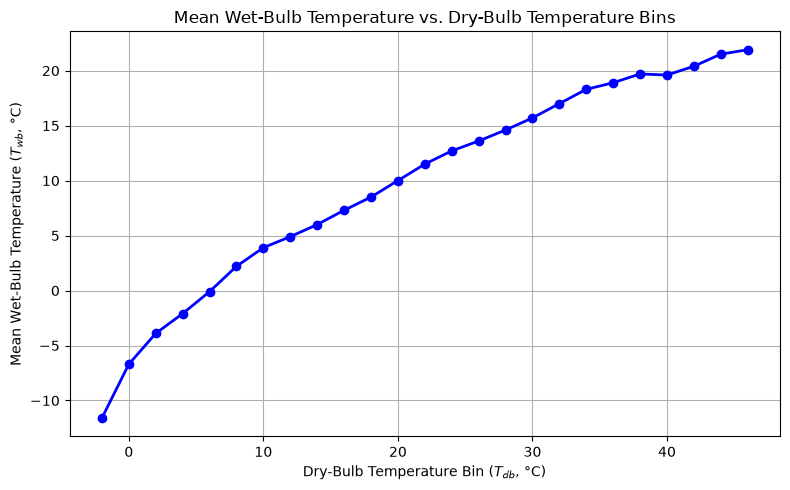

In [254]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(bin_results_df['T_db_bin'], bin_results_df['T_wb_bin'], marker='o', color='b', linestyle='-', linewidth=2)
plt.title('Mean Wet-Bulb Temperature vs. Dry-Bulb Temperature Bins')
plt.xlabel('Dry-Bulb Temperature Bin ($T_{db}$, °C)')
plt.ylabel('Mean Wet-Bulb Temperature ($T_{wb}$, °C)')
plt.grid(True)
plt.tight_layout()
plt.show()

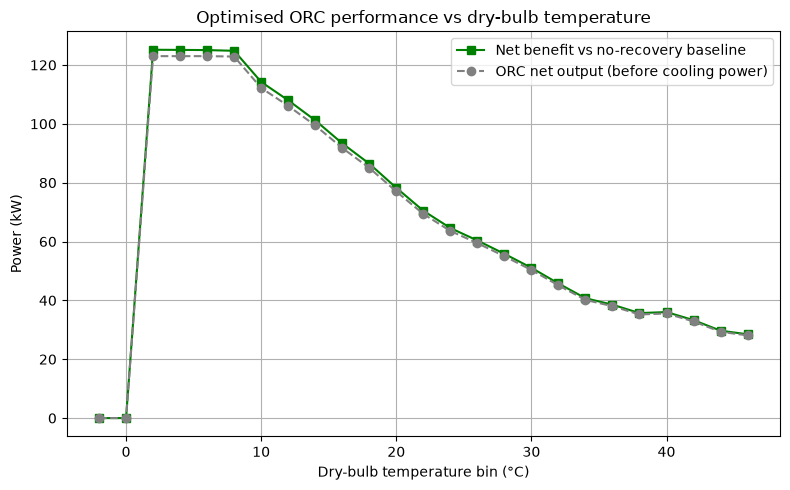

In [257]:
plt.figure(figsize=(8, 5))
plt.plot(bin_results_df['T_db_bin'], bin_results_df['W_net_benefit_kW'],
         marker='s', color='g', label='Net benefit vs no-recovery baseline')
plt.plot(bin_results_df['T_db_bin'], bin_results_df['W_net_orc_kW'],
         marker='o', linestyle='--', color='gray', label='ORC net output (before cooling power)')
plt.xlabel('Dry-bulb temperature bin (°C)')
plt.ylabel('Power (kW)')
plt.title('Optimised ORC performance vs dry-bulb temperature')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()

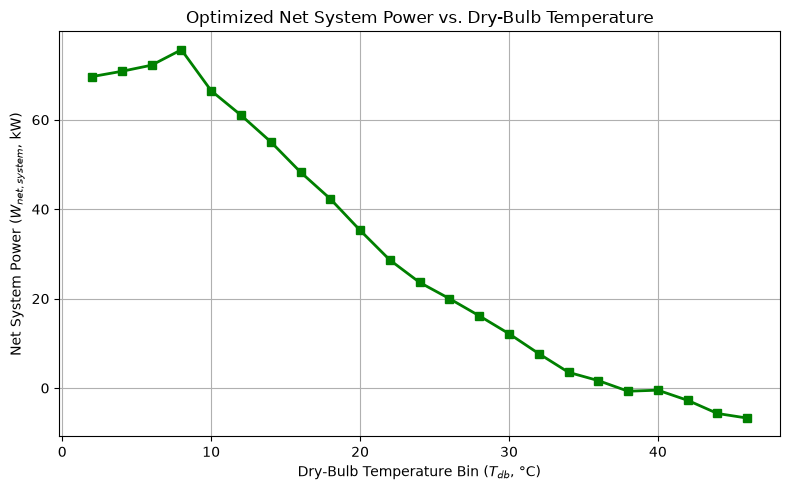

In [258]:
plt.figure(figsize=(8, 5))
# Filter out NaN rows if any sub-zero bins were dropped
valid_df = bin_results_df.dropna(subset=['Optimal_T_evap_C'])

plt.plot(valid_df['T_db_bin'], valid_df['W_net_system_kW'], marker='s', color='g', linestyle='-', linewidth=2)
plt.title('Optimized Net System Power vs. Dry-Bulb Temperature')
plt.xlabel('Dry-Bulb Temperature Bin ($T_{db}$, °C)')
plt.ylabel('Net System Power ($W_{net, system}$, kW)')
plt.grid(True)
plt.tight_layout()
plt.show()

KeyError: 'broad_carnot_efficiency'

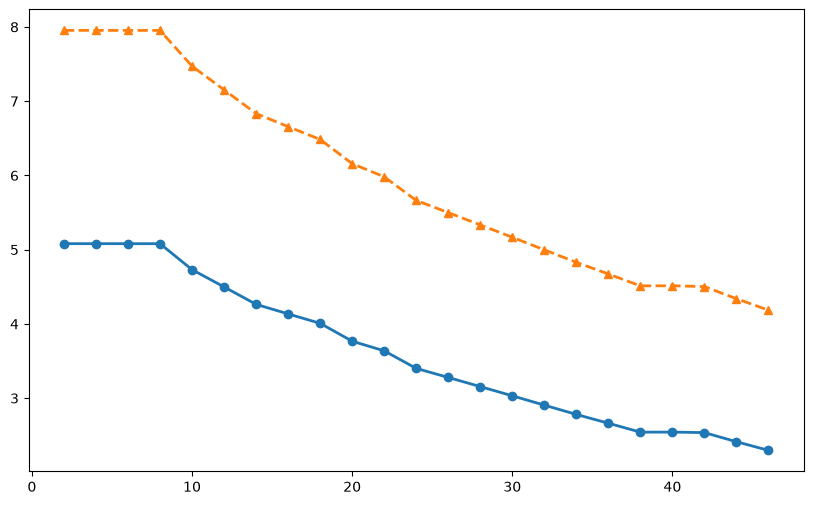

In [259]:
# --- PLOT: Efficiency Comparison with a Restricted X-Axis Range ---
plt.figure(figsize=(10, 6))

# Plot your efficiency data normally using the full dataframe
plt.plot(bin_results_df['T_db_bin'], bin_results_df['ORC_actual_efficiency'], marker='o', label='ORC Actual Efficiency', linewidth=2)
plt.plot(bin_results_df['T_db_bin'], bin_results_df['ORC_carnot_efficiency'], marker='^', linestyle='--', label='ORC Carnot Efficiency', linewidth=2)
plt.plot(bin_results_df['T_db_bin'], bin_results_df['broad_carnot_efficiency'], marker='x', linestyle='-.', label='Broad Reservoir Carnot Efficiency', linewidth=2)

# Manually restrict the x-axis viewable range to cut off before the summer shutdown 
# (e.g., from your minimum dry-bulb up to 28°C or 30°C)
plt.xlim(bin_results_df['T_db_bin'].min(), 28.5)

plt.title("Efficiency Comparison across Operational Dry-Bulb Temperature Bins")
plt.xlabel("Dry-Bulb Temperature Bin (T_db, °C)")
plt.ylabel("Efficiency (%)")
plt.legend()
plt.grid(True)
plt.show()

In [241]:
# 1. Sort the results dataframe by performance (highest net power first)
# This ensures that if we have to drop hours, we drop the least productive bins
bin_results_sorted = bin_results_df.sort_values(by='W_net_system_kW', ascending=False).reset_index(drop=True)

# 2. Accumulate hours up to the 8,000-hour limit
target_hours = 8000
accumulated_hours = 0
active_bins_list = []

for index, row in bin_results_sorted.iterrows():
    hours_in_bin = row['TMY_hours']
    
    if accumulated_hours + hours_in_bin <= target_hours:
        # Take the whole bin
        active_bins_list.append(row)
        accumulated_hours += hours_in_bin
    else:
        # Take only the partial hours needed from this bin to hit exactly 8,000 hours
        partial_hours = target_hours - accumulated_hours
        if partial_hours > 0:
            row_partial = row.copy()
            row_partial['TMY_hours'] = partial_hours
            # Recalculate annual energy for these partial hours
            row_partial['Annual_Net_Energy_MWh'] = (row_partial['W_net_system_kW'] * 1e3 * partial_hours) / 1e6
            active_bins_list.append(row_partial)
            accumulated_hours += partial_hours
        break  # Reached 8,000 hours

# 3. Create the final restricted 8,000-hour DataFrame
operating_df = pd.DataFrame(active_bins_list)

# 4. Calculate total annual figures
total_annual_generation_MWh = operating_df['Annual_Net_Energy_MWh'].sum()
total_active_hours = operating_df['TMY_hours'].sum()

print(f"--- 8,000-Hour Operating Constraint Summary ---")
print(f"Total Active Operating Hours: {total_active_hours} hours")
print(f"Total Annual Net Energy Generated: {total_annual_generation_MWh:,.2f} MWh/year")

# (Optional) View which lowest-producing bins or partial hours were cut
omitted_bins = bin_results_sorted.iloc[len(operating_df):]
if not omitted_bins.empty:
    print(f"\nOmitted or partially trimmed bins (lowest production):")
    print(omitted_bins[['T_db_bin', 'T_wb_bin', 'TMY_hours', 'W_net_system_kW']])

--- 8,000-Hour Operating Constraint Summary ---
Total Active Operating Hours: 8000.0 hours
Total Annual Net Energy Generated: 320.60 MWh/year

Omitted or partially trimmed bins (lowest production):
    T_db_bin  T_wb_bin  TMY_hours  W_net_system_kW
19      44.0      21.5       93.0              0.0
20      42.0      20.4      178.0              0.0
21      -2.0     -11.6       14.0              0.0
22      38.0      19.7      250.0              0.0
23       0.0      -6.7       50.0              0.0
24      46.0      21.9        6.0              0.0
